In [1]:
import cv2
import os
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import numpy as np
from PIL import Image

In [10]:
image_dir = 'activations/five/8'
image_files = os.listdir(image_dir)

image_files = [os.path.join(image_dir, f) for f in image_files if f.endswith('.png')]

images = []

In [11]:
for img_file in image_files:
    img = Image.open(img_file)
    img = np.array(img)
    images.append(img)

In [12]:
images_array = np.array(images)
print(f"Loaded {images_array.shape[0]} images with shape {images_array.shape[1:]}")
n_samples = images_array.shape[0]
images_flat = images_array.reshape(n_samples, -1)
print(f"Flattened images to shape: {images_flat.shape}")
tsne = TSNE(n_components=2, random_state=42)
images_tsne = tsne.fit_transform(images_flat)
print(f"t-SNE result shape: {images_tsne.shape}")

Loaded 64 images with shape (28, 28)
Flattened images to shape: (64, 784)
t-SNE result shape: (64, 2)


In [16]:
# Normalize t-SNE coordinates to [0,1]x[0,1] range
def normalize_to_unit_square(coordinates):
    """
    Normalize coordinates to [0,1]x[0,1] range
    """
    x_min, x_max = coordinates[:, 0].min(), coordinates[:, 0].max()
    y_min, y_max = coordinates[:, 1].min(), coordinates[:, 1].max()
    
    normalized_coords = coordinates.copy()
    normalized_coords[:, 0] = (coordinates[:, 0] - x_min) / (x_max - x_min)
    normalized_coords[:, 1] = (coordinates[:, 1] - y_min) / (y_max - y_min)
    
    return normalized_coords

# Apply normalization
images_tsne_normalized = normalize_to_unit_square(images_tsne)
print(f"Original t-SNE range: X[{images_tsne[:, 0].min():.2f}, {images_tsne[:, 0].max():.2f}], Y[{images_tsne[:, 1].min():.2f}, {images_tsne[:, 1].max():.2f}]")
print(f"Normalized t-SNE range: X[{images_tsne_normalized[:, 0].min():.2f}, {images_tsne_normalized[:, 0].max():.2f}], Y[{images_tsne_normalized[:, 1].min():.2f}, {images_tsne_normalized[:, 1].max():.2f}]")

Original t-SNE range: X[-5.66, 5.29], Y[-3.77, 3.19]
Normalized t-SNE range: X[0.00, 1.00], Y[0.00, 1.00]


Cluster distribution: [ 8  8 16 12 12  8]


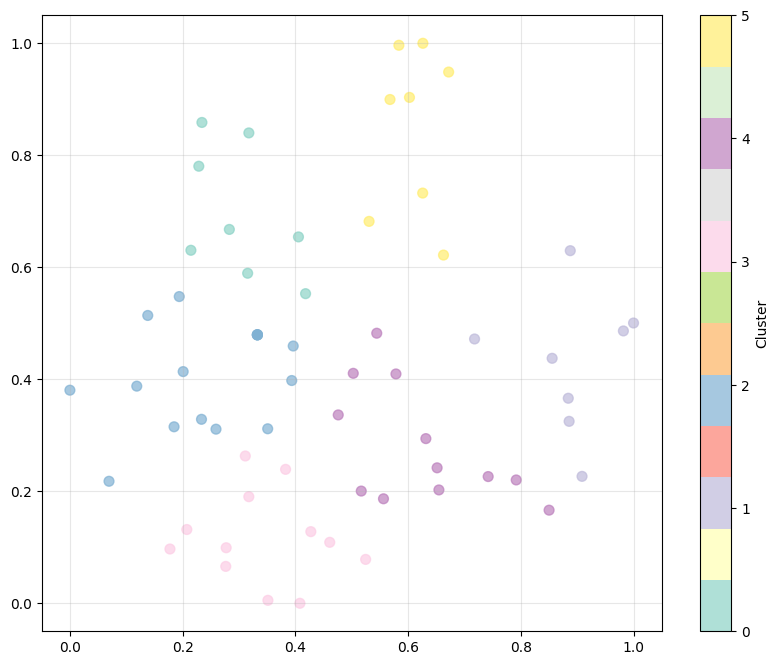

In [19]:
from sklearn.cluster import KMeans

n_clusters = 6
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(images_tsne_normalized)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(images_tsne_normalized[:, 0], images_tsne_normalized[:, 1], 
                     c=cluster_labels, cmap='Set3', alpha=0.7, s=50)
plt.grid(True, alpha=0.3)

plt.colorbar(scatter, label='Cluster')

cluster_counts = np.bincount(cluster_labels)
print(f"Cluster distribution: {cluster_counts}")

plt.show()

Total images: 64
Cluster distribution: [15 15 15  8 11]


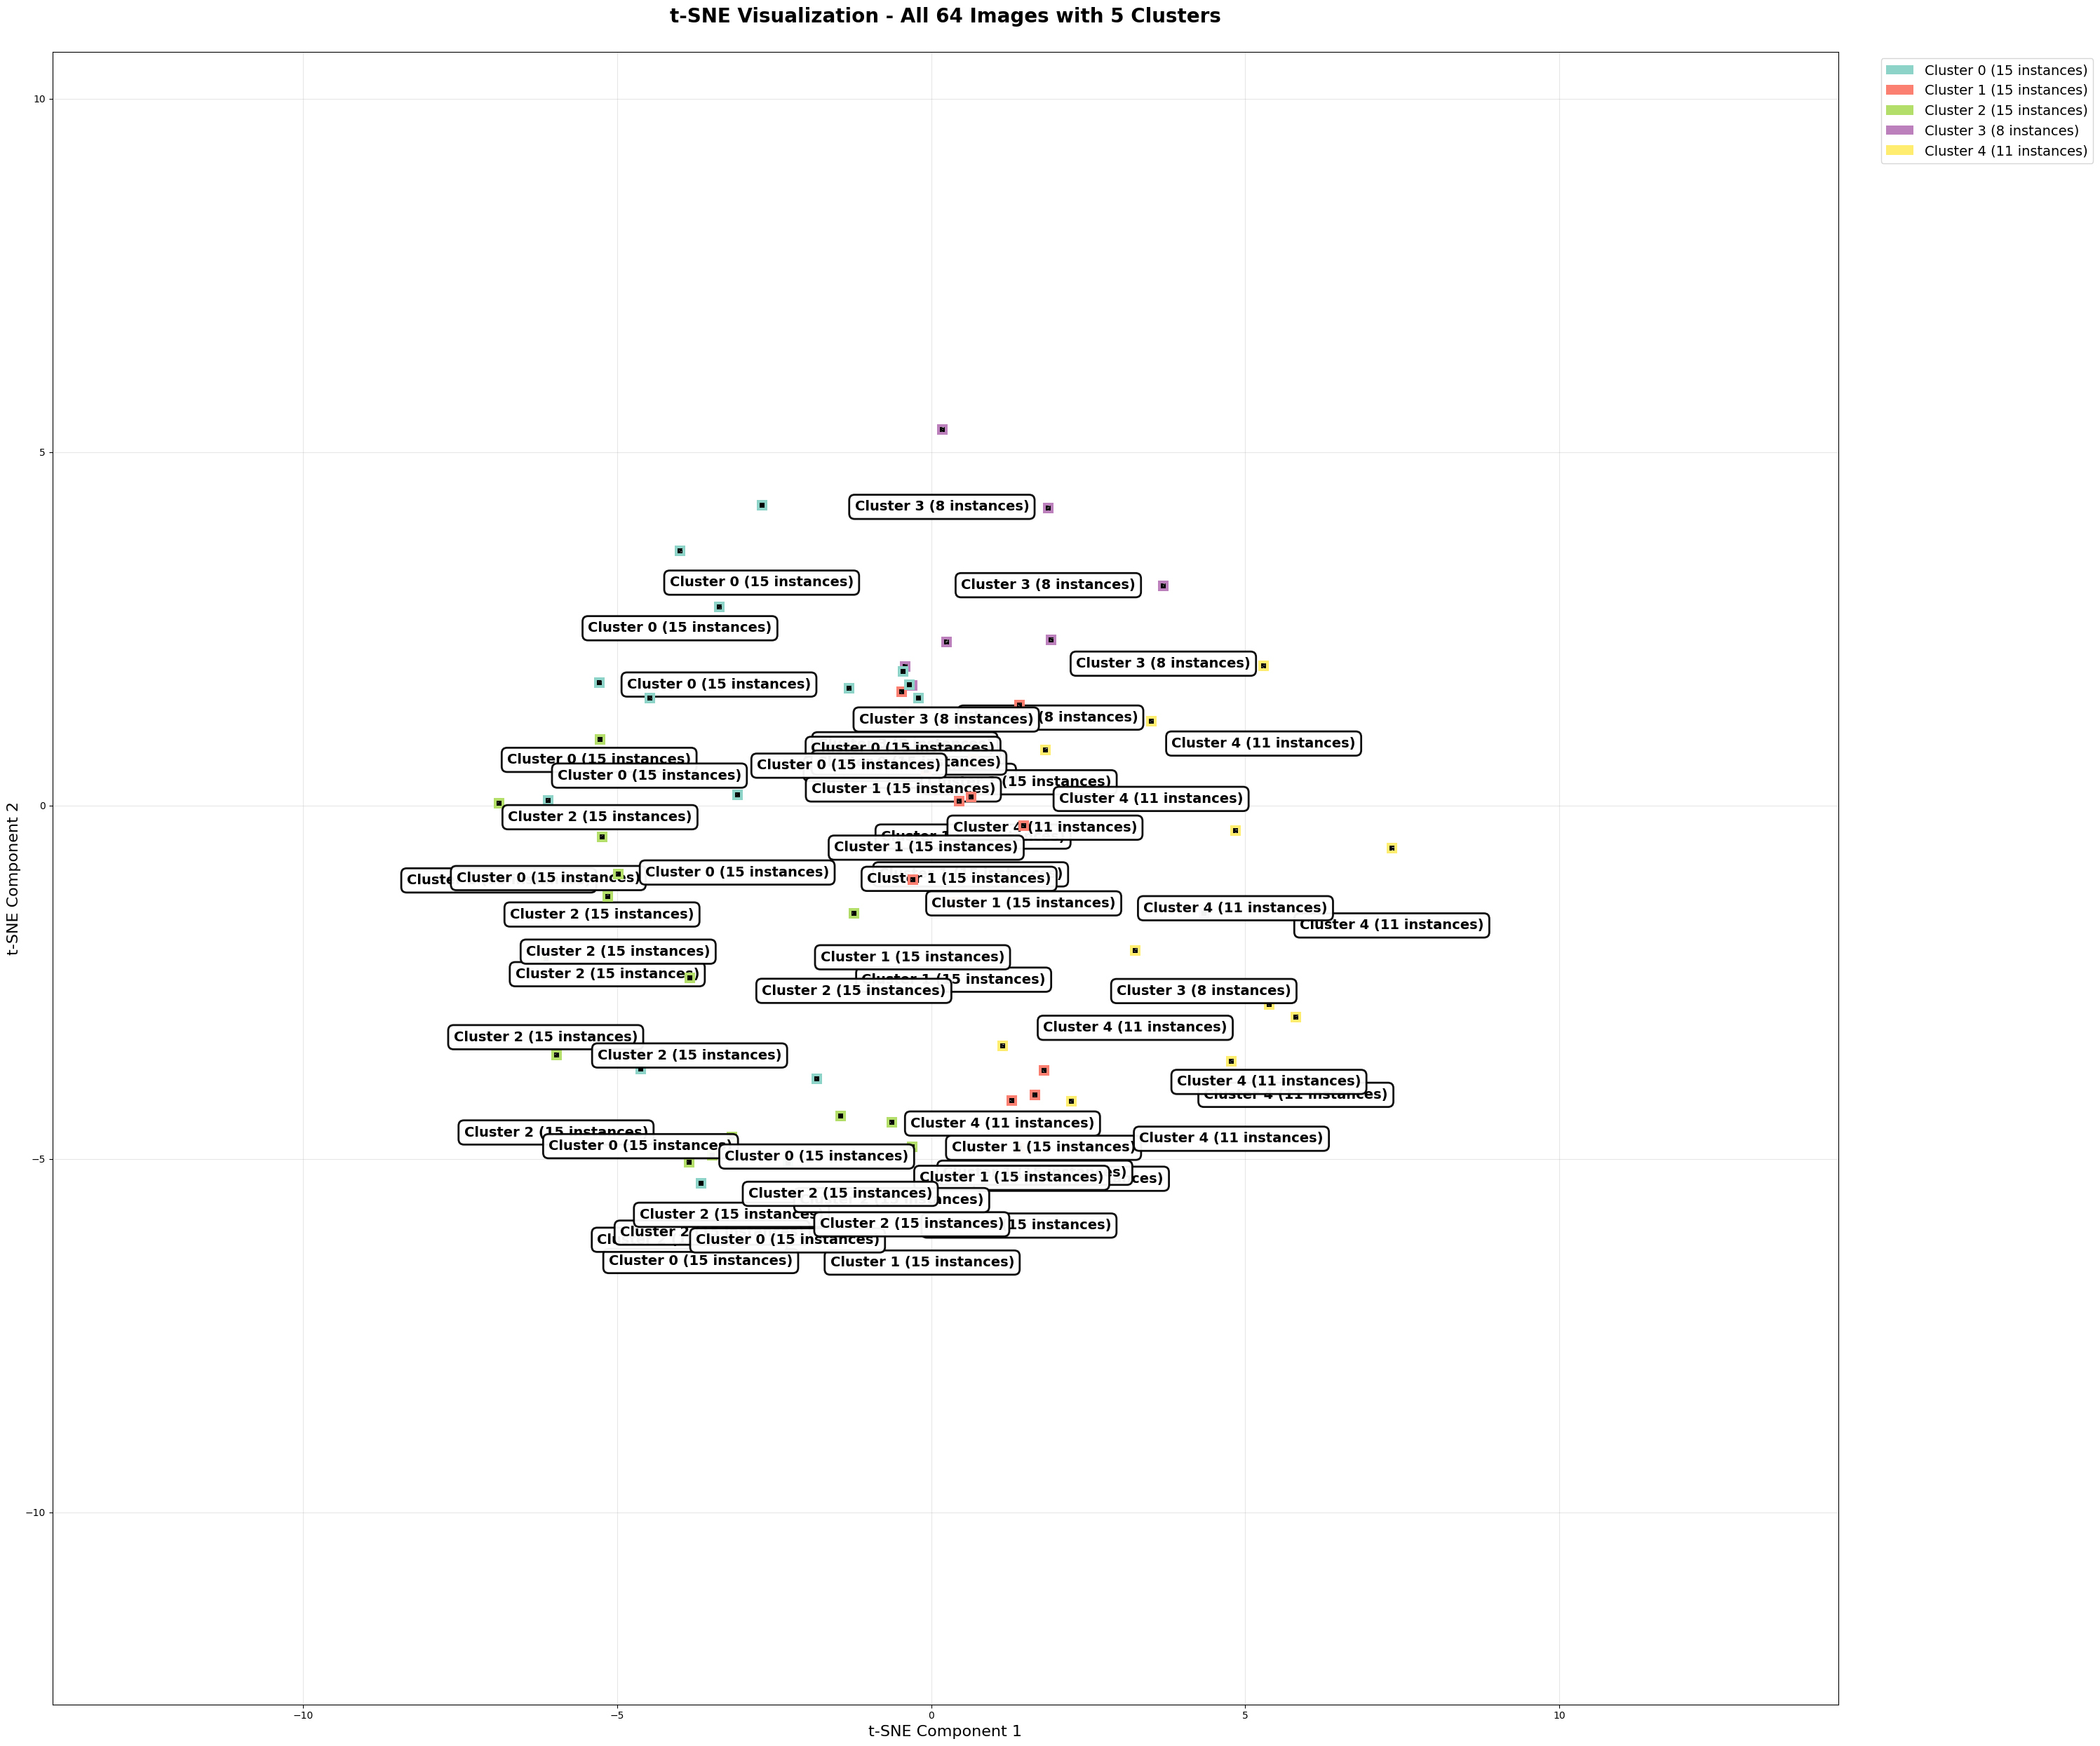

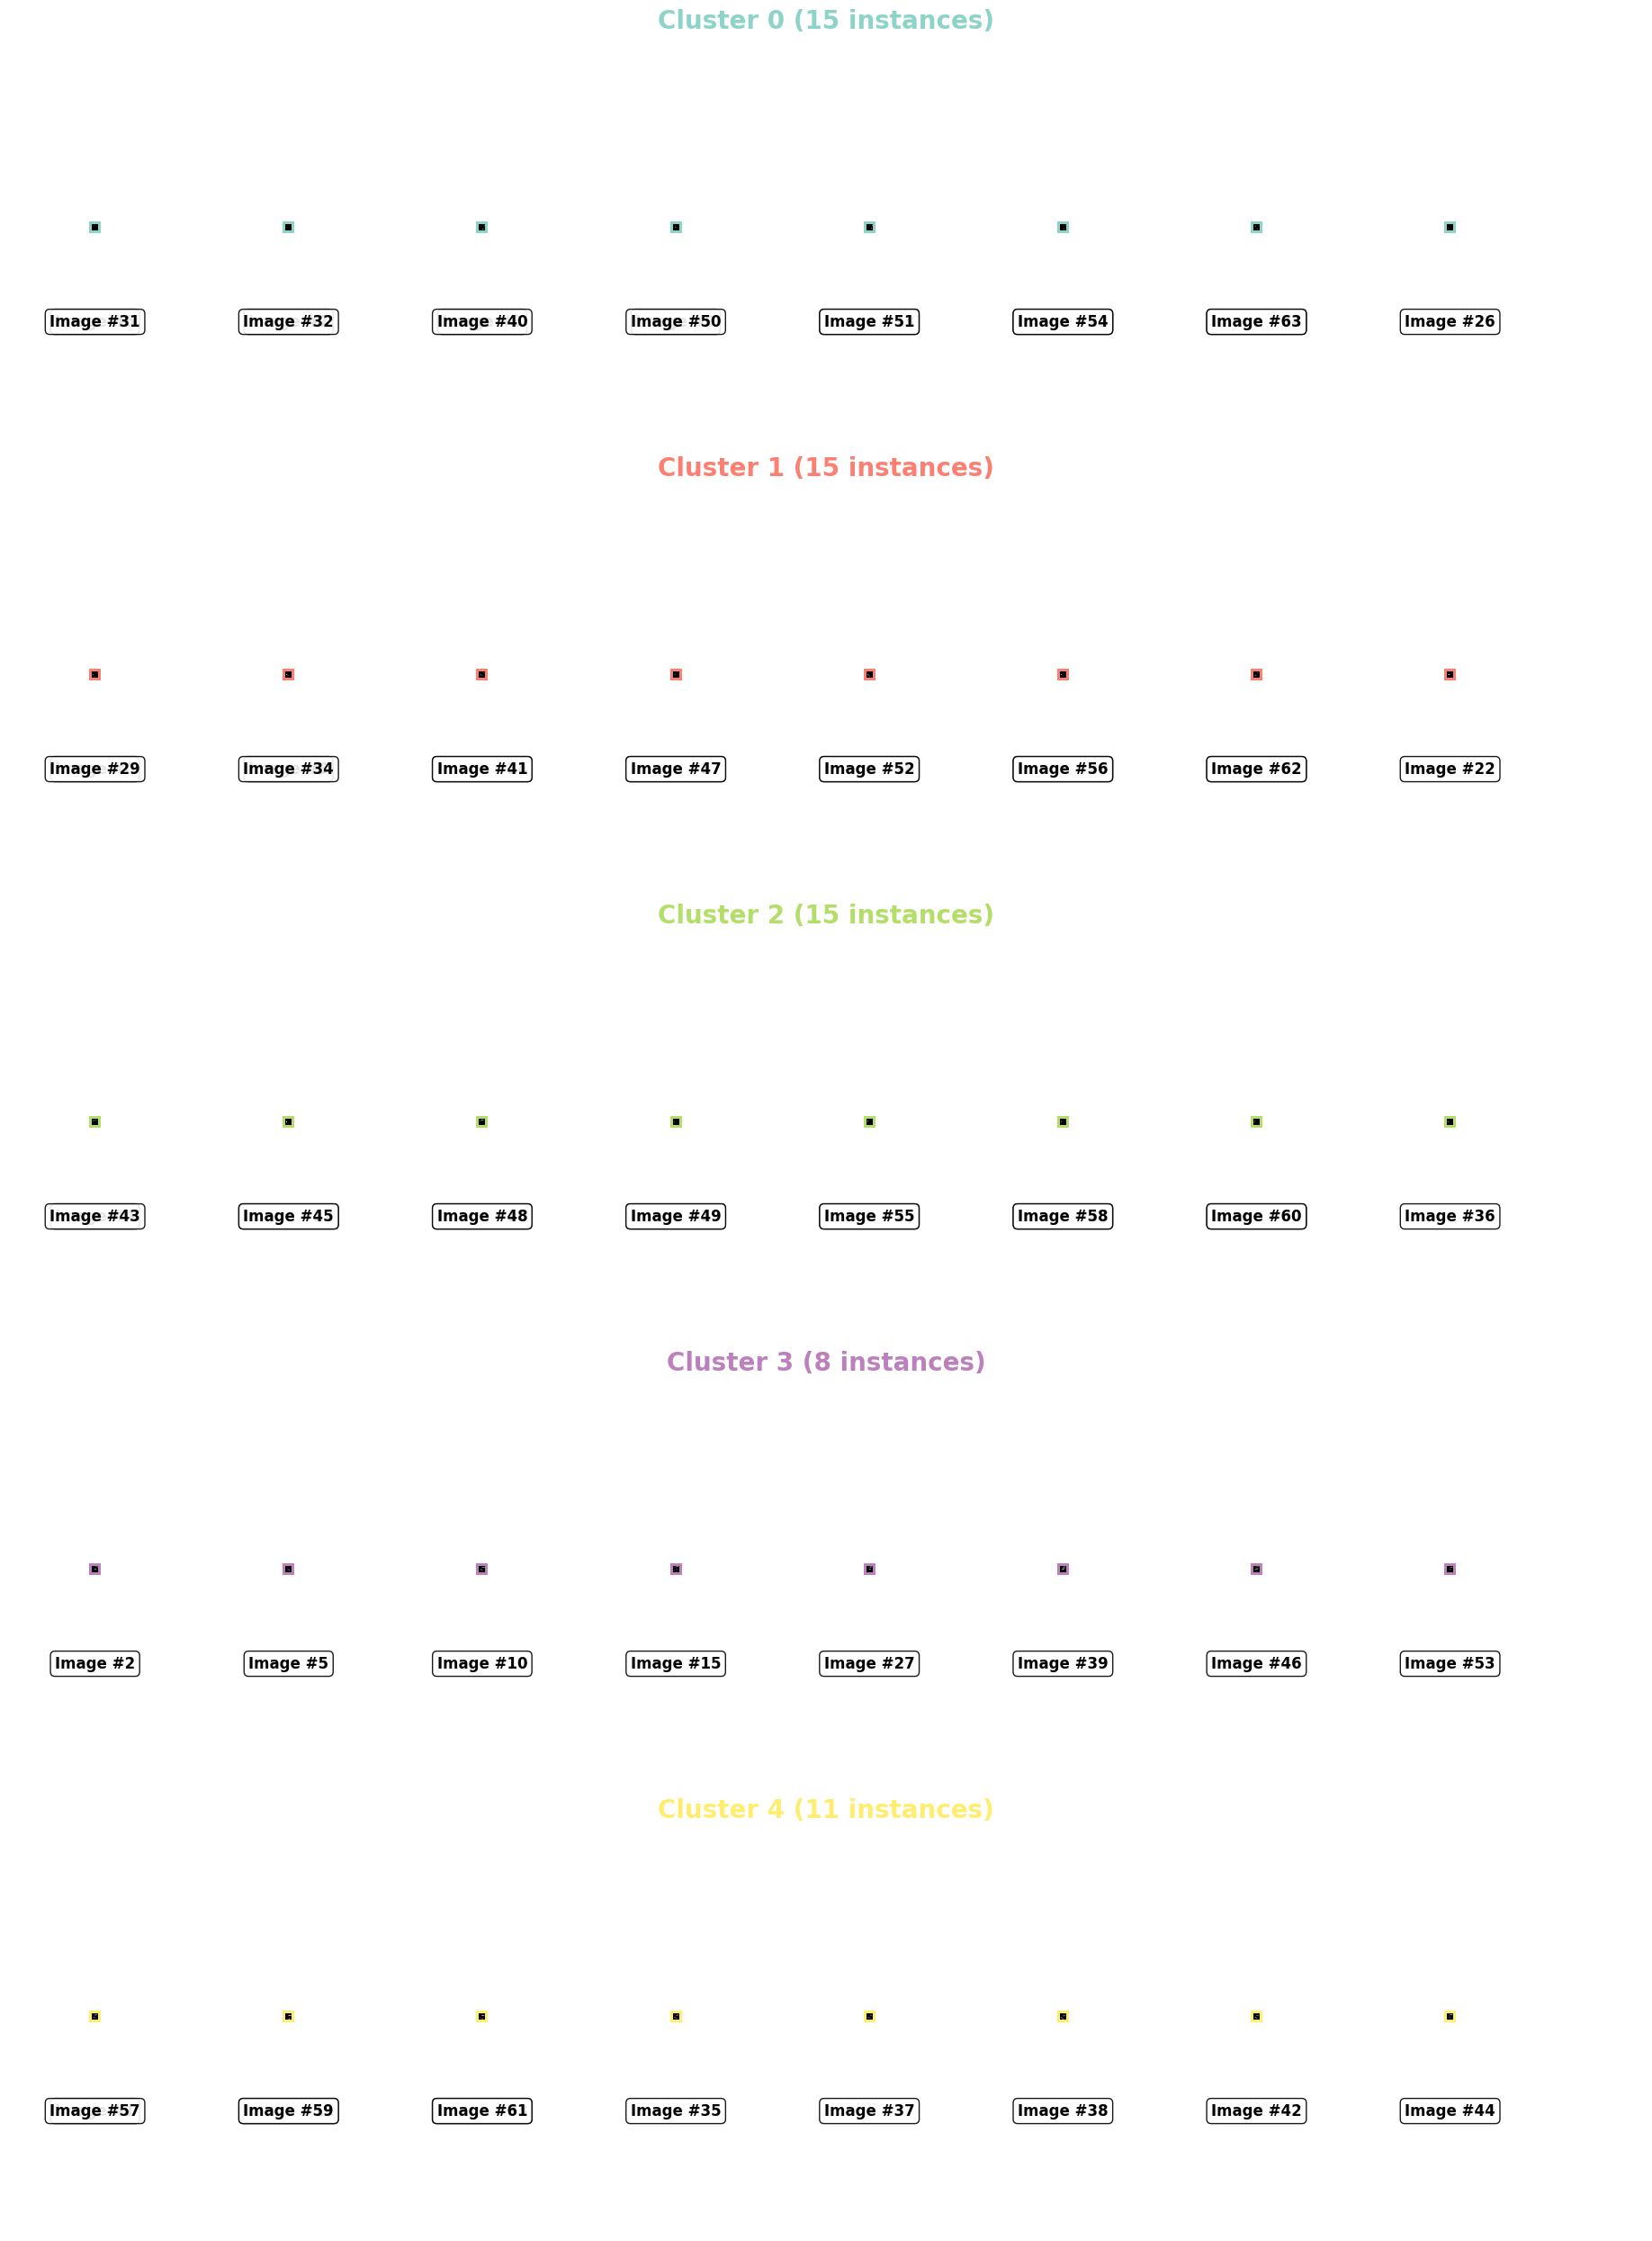

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.cluster import KMeans

# First, create clusters for all images
n_clusters = 5  # Adjust based on your data
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(images_tsne)

print(f"Total images: {len(images)}")
print(f"Cluster distribution: {np.bincount(cluster_labels)}")

def spread_overlapping_points(positions, min_distance=0.5):
    """
    Adjust positions to prevent overlapping while maintaining relative clustering
    """
    adjusted_positions = positions.copy()
    
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            distance = np.linalg.norm(adjusted_positions[i] - adjusted_positions[j])
            if distance < min_distance:
                # Calculate direction to move points apart
                direction = adjusted_positions[j] - adjusted_positions[i]
                if np.linalg.norm(direction) > 0:
                    direction = direction / np.linalg.norm(direction)
                else:
                    direction = np.random.randn(2)
                    direction = direction / np.linalg.norm(direction)
                
                # Move points apart
                offset = (min_distance - distance) / 2
                adjusted_positions[i] -= direction * offset
                adjusted_positions[j] += direction * offset
    
    return adjusted_positions

def plot_all_images_spread_out(images_tsne, images, cluster_labels, image_size=0.12, min_distance=2.0):
    """
    Plot all images with spacing to prevent overlap and clear titles
    """
    # Adjust positions to prevent overlap with larger distance
    spread_positions = spread_overlapping_points(images_tsne, min_distance)
    
    fig, ax = plt.subplots(figsize=(30, 25))  # Larger figure
    
    # Define colors for clusters
    colors = plt.cm.Set3(np.linspace(0, 1, len(np.unique(cluster_labels))))
    
    # Calculate cluster counts
    cluster_counts = np.bincount(cluster_labels)
    
    # Plot all images
    for i in range(len(images)):
        img = images[i]
        
        # Normalize image
        if img.dtype != np.uint8:
            img = ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)
        
        # Convert to RGB if grayscale
        if len(img.shape) == 2:
            img = np.stack([img] * 3, axis=-1)
        
        # Add colored border based on cluster - THICK BORDER
        cluster_color = colors[cluster_labels[i]][:3]
        border_size = 15  # Even thicker border
        
        # Create image with border
        h, w = img.shape[:2]
        bordered_img = np.ones((h + 2*border_size, w + 2*border_size, 3), dtype=np.uint8)
        bordered_img[:, :] = (np.array(cluster_color) * 255).astype(np.uint8)
        bordered_img[border_size:h+border_size, border_size:w+border_size] = img
        
        # Create OffsetImage
        imagebox = OffsetImage(bordered_img, zoom=image_size)
        
        # Position at adjusted coordinates
        ab = AnnotationBbox(imagebox, (spread_positions[i, 0], spread_positions[i, 1]), 
                           frameon=False, pad=0)
        ax.add_artist(ab)
        
        # Add cluster name and count FURTHER below image to avoid overlap
        cluster_text = f'Cluster {cluster_labels[i]} ({cluster_counts[cluster_labels[i]]} instances)'
        ax.text(spread_positions[i, 0], spread_positions[i, 1] - 1.0,  # Moved further down
                cluster_text, 
                fontsize=14, fontweight='bold', ha='center', va='top',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.95, 
                         edgecolor='black', linewidth=2))
    
    # Set plot limits with much more padding for text
    x_min, x_max = spread_positions[:, 0].min(), spread_positions[:, 0].max()
    y_min, y_max = spread_positions[:, 1].min(), spread_positions[:, 1].max()
    
    padding = 0.5  # Much larger padding
    x_range = x_max - x_min
    y_range = y_max - y_min
    
    ax.set_xlim(x_min - padding * x_range, x_max + padding * x_range)
    ax.set_ylim(y_min - padding * y_range - 2.0, y_max + padding * y_range)  # Extra space at bottom
    
    ax.set_title(f't-SNE Visualization - All {len(images)} Images with {n_clusters} Clusters', 
                fontsize=20, fontweight='bold', pad=30)
    ax.set_xlabel('t-SNE Component 1', fontsize=16)
    ax.set_ylabel('t-SNE Component 2', fontsize=16)
    ax.grid(True, alpha=0.3)
    
    # Add legend with cluster names and counts
    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i], 
                                   label=f'Cluster {i} ({cluster_counts[i]} instances)') 
                      for i in range(n_clusters)]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=14)
    
    plt.tight_layout()
    plt.show()

# Alternative: Grid layout with better spacing
def plot_images_in_grid():
    """
    Arrange images in a grid layout grouped by clusters with clear spacing
    """
    cluster_counts = np.bincount(cluster_labels)
    fig, axes = plt.subplots(n_clusters, 1, figsize=(25, 5*n_clusters))  # More height per cluster
    if n_clusters == 1:
        axes = [axes]
    
    colors = plt.cm.Set3(np.linspace(0, 1, n_clusters))
    
    for cluster_id in range(n_clusters):
        cluster_indices = np.where(cluster_labels == cluster_id)[0]
        
        ax = axes[cluster_id]
        # Title with more padding
        ax.set_title(f'Cluster {cluster_id} ({cluster_counts[cluster_id]} instances)', 
                    fontsize=20, color=colors[cluster_id], fontweight='bold', pad=30)
        
        # Calculate grid dimensions
        n_images_in_cluster = len(cluster_indices)
        cols = min(8, n_images_in_cluster)  # Fewer images per row for more space
        
        for idx, img_idx in enumerate(cluster_indices):
            img = images[img_idx]
            
            # Normalize image
            if img.dtype != np.uint8:
                img = ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)
            
            # Position in row with more spacing
            x_pos = (idx % cols) * 1.8  # Increased spacing
            y_pos = 0
            
            # Convert to RGB if grayscale
            if len(img.shape) == 2:
                img = np.stack([img] * 3, axis=-1)
            
            # Add very thick border
            border_size = 12  # Thick border
            h, w = img.shape[:2]
            bordered_img = np.ones((h + 2*border_size, w + 2*border_size, 3), dtype=np.uint8)
            bordered_img[:, :] = (np.array(colors[cluster_id][:3]) * 255).astype(np.uint8)
            bordered_img[border_size:h+border_size, border_size:w+border_size] = img
            
            imagebox = OffsetImage(bordered_img, zoom=0.18)  # Slightly larger images
            ab = AnnotationBbox(imagebox, (x_pos, y_pos), frameon=False, pad=0)
            ax.add_artist(ab)
            
            # Add image index well below image
            ax.text(x_pos, y_pos - 0.8, f'Image #{img_idx}', 
                   fontsize=12, ha='center', va='top', fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9))
        
        ax.set_xlim(-0.8, cols * 1.8)
        ax.set_ylim(-2.0, 1.5)  # More space at bottom
        ax.set_aspect('equal')
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

# Plot with better spacing
plot_all_images_spread_out(images_tsne_normalized, images, cluster_labels, image_size=0.18, min_distance=2.5)

# Also show grid layout
plot_images_in_grid()

Total images: 64
Cluster distribution: [15 15 15  8 11]


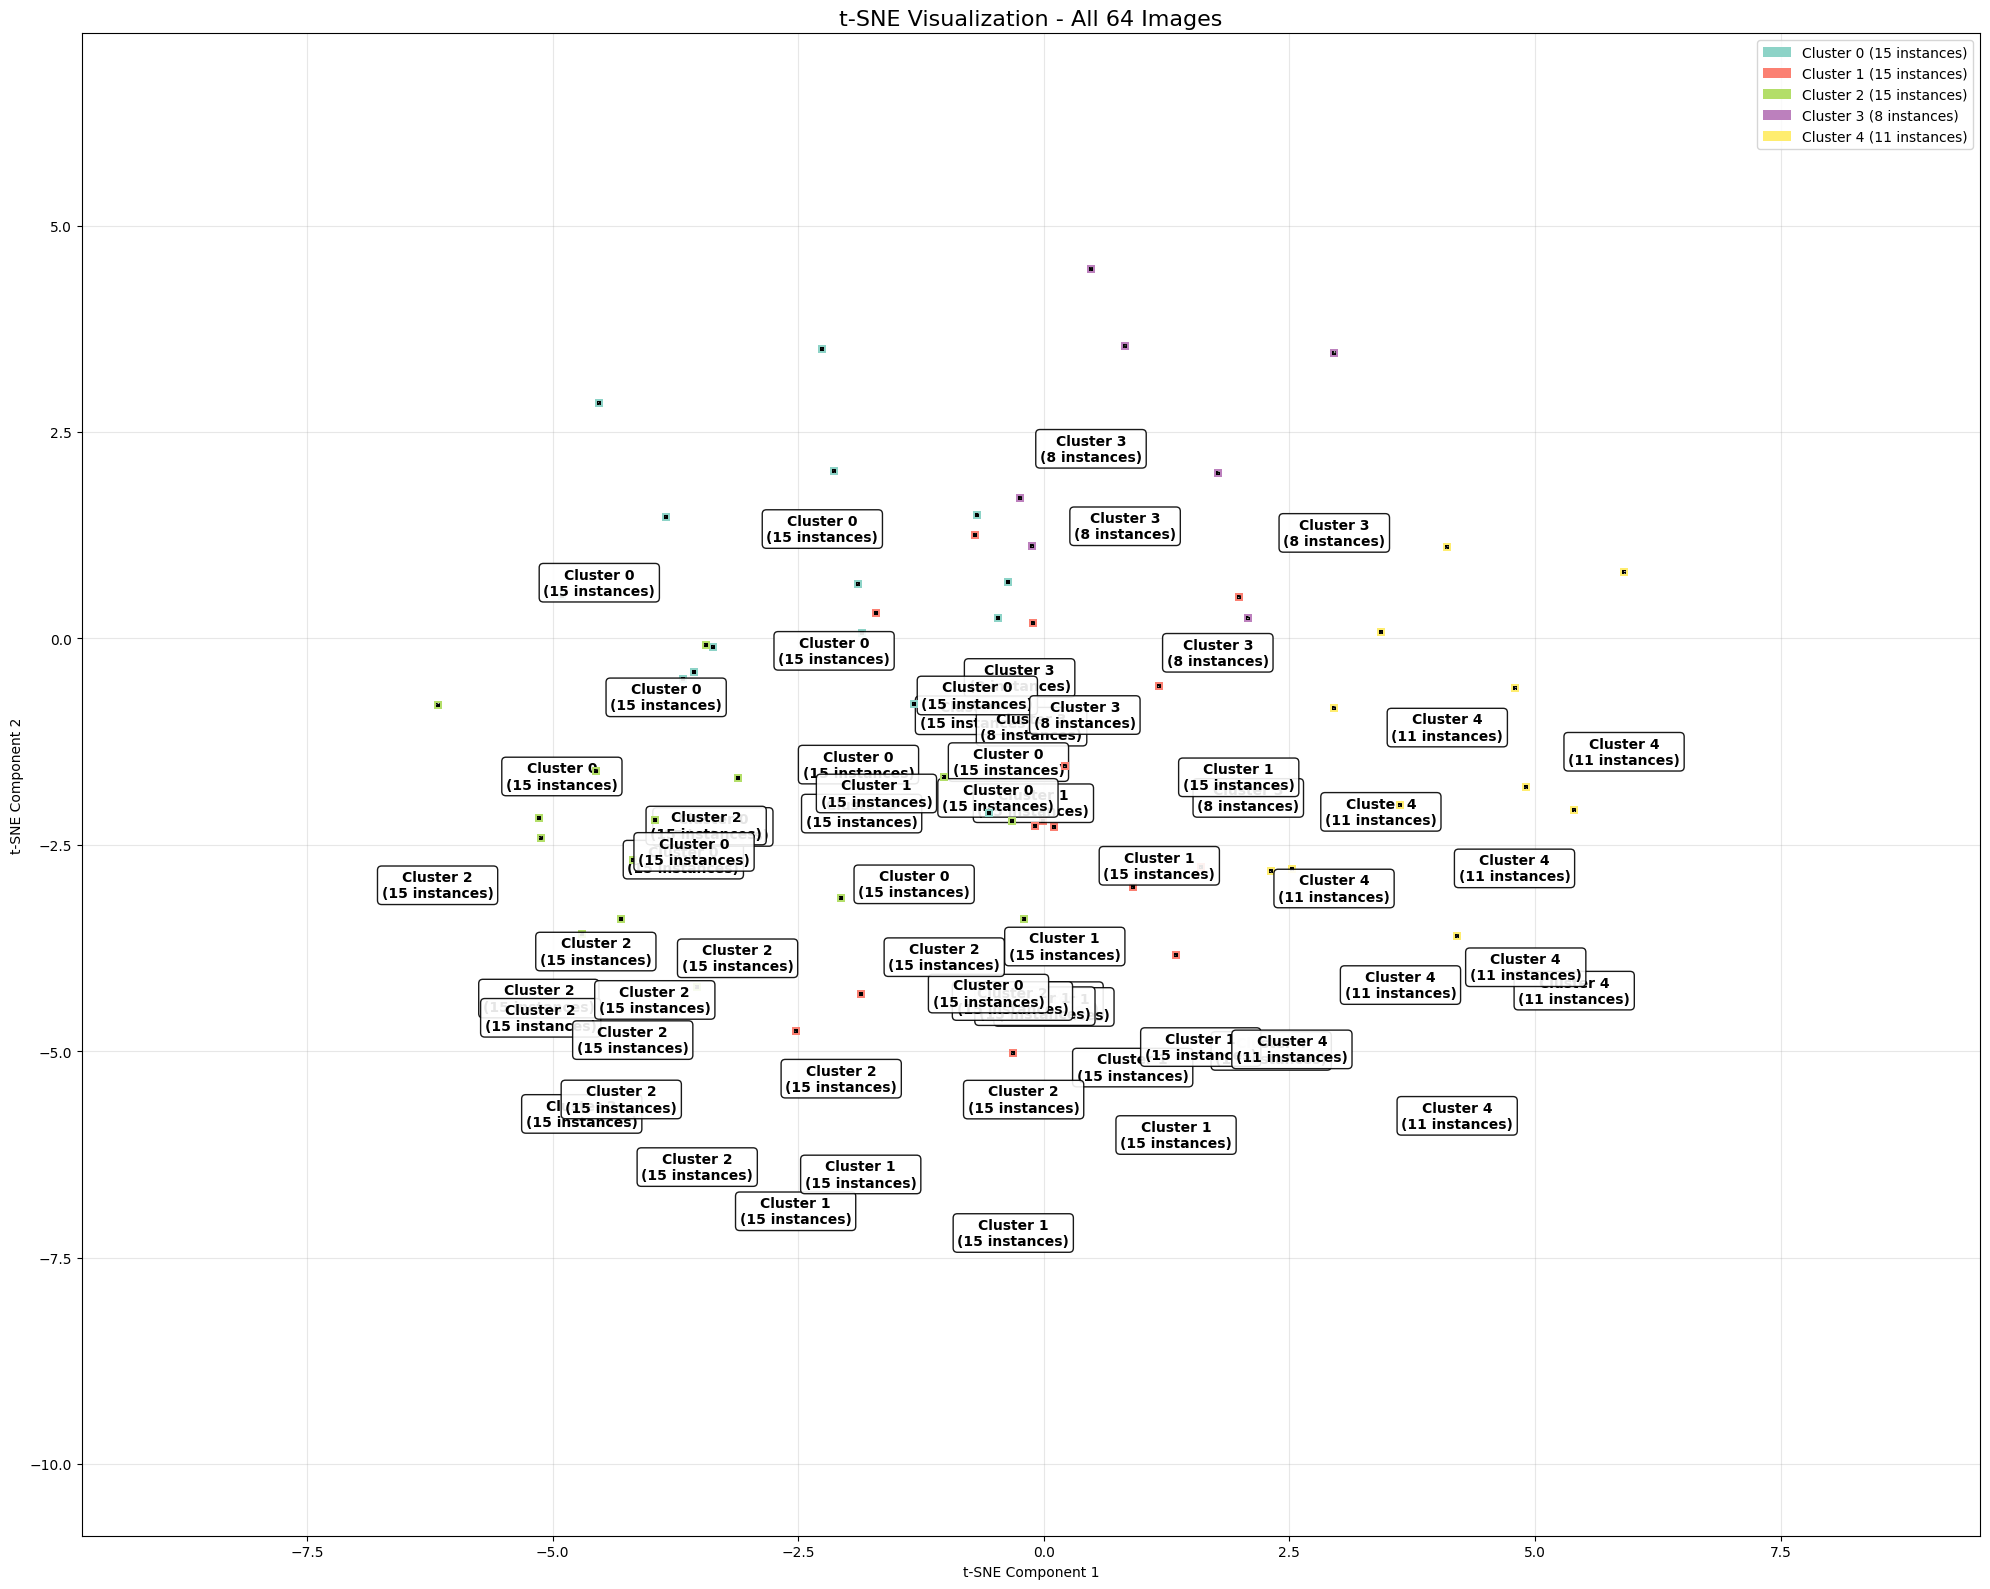

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.cluster import KMeans

# First, create clusters for all images
n_clusters = 5  # Adjust based on your data
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(images_tsne)

print(f"Total images: {len(images)}")
print(f"Cluster distribution: {np.bincount(cluster_labels)}")

def spread_overlapping_points(positions, min_distance=1.5):
    """
    Adjust positions to prevent overlapping while maintaining relative clustering
    """
    adjusted_positions = positions.copy()
    
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            distance = np.linalg.norm(adjusted_positions[i] - adjusted_positions[j])
            if distance < min_distance:
                # Calculate direction to move points apart
                direction = adjusted_positions[j] - adjusted_positions[i]
                if np.linalg.norm(direction) > 0:
                    direction = direction / np.linalg.norm(direction)
                else:
                    direction = np.random.randn(2)
                    direction = direction / np.linalg.norm(direction)
                
                # Move points apart
                offset = (min_distance - distance) / 2
                adjusted_positions[i] -= direction * offset
                adjusted_positions[j] += direction * offset
    
    return adjusted_positions

def plot_all_images_with_labels(images_tsne, images, cluster_labels, image_size=0.15):
    """
    Plot all images with cluster labels positioned well below each image
    """
    # Spread out positions
    spread_positions = spread_overlapping_points(images_tsne, min_distance=1.8)
    
    fig, ax = plt.subplots(figsize=(20, 16))
    
    # Define colors for clusters
    colors = plt.cm.Set3(np.linspace(0, 1, len(np.unique(cluster_labels))))
    cluster_counts = np.bincount(cluster_labels)
    
    # Plot all images
    for i in range(len(images)):
        img = images[i]
        
        # Normalize image
        if img.dtype != np.uint8:
            img = ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)
        
        # Convert to RGB if grayscale
        if len(img.shape) == 2:
            img = np.stack([img] * 3, axis=-1)
        
        # Add thick colored border
        cluster_color = colors[cluster_labels[i]][:3]
        border_size = 10
        
        h, w = img.shape[:2]
        bordered_img = np.ones((h + 2*border_size, w + 2*border_size, 3), dtype=np.uint8)
        bordered_img[:, :] = (np.array(cluster_color) * 255).astype(np.uint8)
        bordered_img[border_size:h+border_size, border_size:w+border_size] = img
        
        # Place image
        imagebox = OffsetImage(bordered_img, zoom=image_size)
        ab = AnnotationBbox(imagebox, (spread_positions[i, 0], spread_positions[i, 1]), 
                           frameon=False, pad=0)
        ax.add_artist(ab)
        
        # Place text MUCH further below the image
        cluster_text = f'Cluster {cluster_labels[i]}\n({cluster_counts[cluster_labels[i]]} instances)'
        ax.text(spread_positions[i, 0], spread_positions[i, 1] - 2.0,  # Much further down
                cluster_text, 
                fontsize=10, fontweight='bold', ha='center', va='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9, 
                         edgecolor='black'))
    
    # Set plot limits with extra space at bottom for text
    x_min, x_max = spread_positions[:, 0].min(), spread_positions[:, 0].max()
    y_min, y_max = spread_positions[:, 1].min(), spread_positions[:, 1].max()
    
    padding = 0.3
    x_range = x_max - x_min
    y_range = y_max - y_min
    
    ax.set_xlim(x_min - padding * x_range, x_max + padding * x_range)
    ax.set_ylim(y_min - padding * y_range - 3.0, y_max + padding * y_range)  # Extra space at bottom
    
    ax.set_title(f't-SNE Visualization - All {len(images)} Images', fontsize=16)
    ax.set_xlabel('t-SNE Component 1')
    ax.set_ylabel('t-SNE Component 2')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i], 
                                   label=f'Cluster {i} ({cluster_counts[i]} instances)') 
                      for i in range(n_clusters)]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    plt.tight_layout()
    plt.show()

# Plot with proper spacing
plot_all_images_with_labels(images_tsne_normalized, images, cluster_labels, image_size=0.12)